# Predicción del valor de mercado de autos usados para Rusty Bargain

## Introducción
El servicio de venta de autos usados **Rusty Bargain** está desarrollando una nueva aplicación móvil y web con el propósito de atraer clientes potenciales, permitiéndoles conocer de manera rápida y confiable el valor de mercado de su vehículo. 

Para construir el motor de tasación de esta aplicación, se dispone de un conjunto de datos históricos que reúne más de 350,000 registros con especificaciones técnicas, versiones de equipamiento, kilometraje, historial de reparaciones y precios de venta publicados. El reto consiste en desarrollar y evaluar distintos modelos de aprendizaje automático (*machine learning*) que logren un equilibrio óptimo entre precisión en la estimación y eficiencia computacional.

---

## Objetivos del proyecto
Desarrollar, entrenar y seleccionar un modelo predictivo para determinar el precio de mercado (`Price`) de un automóvil usado, evaluando su desempeño bajo tres pilares fundamentales definidos por el negocio:
1. **Calidad de la predicción:** Minimizar el error de estimación utilizando la **Raíz del Error Cuadrático Medio (RECM / RMSE)** como métrica principal.
2. **Velocidad de predicción:** Garantizar tiempos de inferencia mínimos para ofrecer respuestas en tiempo real dentro de la aplicación.
3. **Tiempo de entrenamiento:** Mantener tiempos de ajuste razonables para facilitar el reentrenamiento periódico del modelo en producción.

---

## Plan de trabajo
Para cumplir con los requerimientos técnicos y criterios de evaluación, el proyecto se ejecutará en tres etapas estructuradas:

* **Etapa 1: Preparación y limpieza de datos**
  * Exploración inicial de tipos de datos, distribuciones y valores ausentes.
  * Eliminación de variables administrativas sin relevancia técnica (`DateCrawled`, `DateCreated`, `LastSeen`, `PostalCode`, `RegistrationMonth`, `NumberOfPictures`).
  * Filtrado e imputación de valores atípicos en el precio (`Price`), año de matriculación (`RegistrationYear`) y potencia (`Power`).
  * Tratamiento de valores nulos en variables categóricas y eliminación de registros duplicados.

* **Etapa 2: Entrenamiento y ajuste de modelos**
  * División de los datos en conjuntos de entrenamiento (60%), validación (20%) y prueba (20%).
  * Aplicación de estrategias de codificación adecuadas según cada familia de algoritmos (*One-Hot Encoding* y escalado para modelos lineales, *Ordinal Encoding* para árboles de *scikit-learn*, y manejo nativo de categorías para *LightGBM*).
  * Implementación de una función unificada para entrenar, predecir y medir tiempos de ejecución (`%%time` y cronometraje exacto) sin duplicación de código.
  * Entrenamiento comparativo de **Regresión Lineal** (prueba de cordura), **Árbol de Decisión**, **Bosque Aleatorio** y **LightGBM** con distintas configuraciones de hiperparámetros.

* **Etapa 3: Análisis comparativo y conclusiones**
  * Contraste visual y tabular de los modelos en función de su RECM, tiempo de entrenamiento y tiempo de predicción.
  * Selección y justificación técnica del modelo óptimo para su despliegue en la aplicación de Rusty Bargain.


## Inicialización

Para construir el entorno computacional necesario y llevar a cabo las operaciones de aprendizaje automático (*Machine Learning*), manipulación de datos y visualización, se procede a importar un ecosistema de librerías especializadas y estandarizadas en la industria de la ciencia de datos:

* **Manipulación y cálculo numérico (`pandas`, `numpy`):** Para la carga, estructuración, limpieza e imputación eficiente del conjunto de datos tabular.
* **Control de rendimiento (`time`):** Para medir con precisión los tiempos de entrenamiento e inferencia de cada algoritmo.
* **Visualización (`matplotlib`):** Para generar gráficos comparativos sobre la calidad y velocidad de los modelos.
* **Formatear texto (`IPython`)** Para importar dos herramientas específicas (display y Markdown) que sirven para mostrar textos con formato elegante dentro de entornos interactivos.
* **Preprocesamiento y modelado (`scikit-learn`, `lightgbm`):** Para dividir los datos, codificar variables categóricas, escalar características numéricas, entrenar algoritmos lineales, árboles de decisión, ensambles y modelos de potenciación del gradiente (*gradient boosting*), así como evaluar su desempeño mediante la métrica **RECM**.


In [1]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
import lightgbm as lgb

### Carga y exploración inicial de los datos
Con el entorno de trabajo inicializado, se procede a realizar la carga del conjunto de datos históricos proporcionado por **Rusty Bargain**. En esta etapa se verifica la correcta lectura del archivo y se lleva a cabo una inspección diagnóstica preliminar para evaluar las dimensiones del dataset, los tipos de datos asignados a cada característica, la presencia de valores ausentes y la existencia de registros duplicados antes de iniciar el proceso de depuración.

In [2]:
# =======================
# CARGAR EL DATASET df
# =======================
try:
    df = pd.read_csv('/datasets/car_data.csv')
except FileNotFoundError:
    df = pd.read_csv('car_data.csv')

print('==============================')
print("--- INFORMACIÓN GENERAL ---")
print('==============================')
df.info()

print('============================')
print("--- PRIMERAS 5 FILAS ---")
print('============================')
display(df.head())

print('=======================================')
print("--- RESUMEN ESTADÍSTICO NUMÉRICO ---")
print('=======================================')
display(df.describe())

print('============================')
print("--- VALORES AUSENTES ---")
print('============================')
print(df.isna().sum())

print('==============================')
print("--- DUPLICADOS EXACTOS ---")
print('==============================')
print(df.duplicated().sum())


--- INFORMACIÓN GENERAL ---
<class 'pandas.DataFrame'>
RangeIndex: 354369 entries, 0 to 354368
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   DateCrawled        354369 non-null  str  
 1   Price              354369 non-null  int64
 2   VehicleType        316879 non-null  str  
 3   RegistrationYear   354369 non-null  int64
 4   Gearbox            334536 non-null  str  
 5   Power              354369 non-null  int64
 6   Model              334664 non-null  str  
 7   Mileage            354369 non-null  int64
 8   RegistrationMonth  354369 non-null  int64
 9   FuelType           321474 non-null  str  
 10  Brand              354369 non-null  str  
 11  NotRepaired        283215 non-null  str  
 12  DateCreated        354369 non-null  str  
 13  NumberOfPictures   354369 non-null  int64
 14  PostalCode         354369 non-null  int64
 15  LastSeen           354369 non-null  str  
dtypes: int64(7), str(9)
m

,DateCrawled,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Mileage,RegistrationMonth,FuelType,Brand,NotRepaired,DateCreated,NumberOfPictures,PostalCode,LastSeen
0,24/03/2016 11:52,480,NaN,1993,manual,0,golf,150000,0,petrol,volkswagen,NaN,24/03/2016 00:00,0,70435,07/04/2016 03:16
1,24/03/2016 10:58,18300,coupe,2011,manual,190,NaN,125000,5,gasoline,audi,yes,24/03/2016 00:00,0,66954,07/04/2016 01:46
2,14/03/2016 12:52,9800,suv,2004,auto,163,grand,125000,8,gasoline,jeep,NaN,14/03/2016 00:00,0,90480,05/04/2016 12:47
3,17/03/2016 16:54,1500,small,2001,manual,75,golf,150000,6,petrol,volkswagen,no,17/03/2016 00:00,0,91074,17/03/2016 17:40
4,31/03/2016 17:25,3600,small,2008,manual,69,fabia,90000,7,gasoline,skoda,no,31/03/2016 00:00,0,60437,06/04/2016 10:17


--- RESUMEN ESTADÍSTICO NUMÉRICO ---


,Price,RegistrationYear,Power,Mileage,RegistrationMonth,NumberOfPictures,PostalCode
count,354369.000000,354369.000000,354369.000000,354369.000000,354369.000000,354369.0,354369.000000
mean,4416.656776,2004.234448,110.094337,128211.172535,5.714645,0.0,50508.689087
std,4514.158514,90.227958,189.850405,37905.341530,3.726421,0.0,25783.096248
min,0.000000,1000.000000,0.000000,5000.000000,0.000000,0.0,1067.000000
25%,1050.000000,1999.000000,69.000000,125000.000000,3.000000,0.0,30165.000000
50%,2700.000000,2003.000000,105.000000,150000.000000,6.000000,0.0,49413.000000
75%,6400.000000,2008.000000,143.000000,150000.000000,9.000000,0.0,71083.000000
max,20000.000000,9999.000000,20000.000000,150000.000000,12.000000,0.0,99998.000000


--- VALORES AUSENTES ---
DateCrawled              0
Price                    0
VehicleType          37490
RegistrationYear         0
Gearbox              19833
Power                    0
Model                19705
Mileage                  0
RegistrationMonth        0
FuelType             32895
Brand                    0
NotRepaired          71154
DateCreated              0
NumberOfPictures         0
PostalCode               0
LastSeen                 0
dtype: int64
--- DUPLICADOS EXACTOS ---
262


#### Hallazgos clave en los datos
* **Columnas irrelevantes para el valor de mercado**: `DateCrawled`, `DateCreated`, `LastSeen`, `PostalCode`, `RegistrationMonth` y `NumberOfPictures` (que además es `0` en todas las filas) no aportan valor predictivo sobre las características técnicas del vehículo y solo añaden ruido o dimensionalidad innecesaria.
* **Anomalías en la variable objetivo (Price)**: Hay autos con precio `0` (o muy cercano a `0`, como subastas o errores de publicación). Entrenar un modelo con precios en `0` distorsiona el error RECM.
* **Anomalías en características numéricas**:
	* `RegistrationYear`: Tiene valores imposibles como `1000` o `9999`. Además, viendo las fechas de `DateCrawled` (año `2016`), ningún auto puede estar matriculado después de 2016.
	* `Power`: Tiene valores en `0` y valores absurdos de hasta `20000` CV.
* **Valores ausentes en categóricas**: `VehicleType`, `Gearbox`, `Model`, `FuelType` y `NotRepaired` tienen miles de valores nulos. En vez de borrar más de 100,000 filas, se puede imputarlos como `'unknown'` (desconocido), ya que el hecho de que un vendedor omita si el auto fue reparado o su tipo de caja es información útil para el modelo.
* **Duplicados**: Existen 262 duplicados exactos antes de eliminar las fechas de rastreo y códigos postales, los cuales serán eliminados para preservar los anuncios legítimos de vehículos comunes.

### Diagnóstico y cuantificación de anomalías

Tras la exploración general del conjunto de datos, se realiza una inspección focalizada sobre las variables críticas (`DateCrawled`, `Price`, `RegistrationYear` y `Power`) para cuantificar el volumen exacto de registros incoherentes o atípicos antes de definir las reglas de filtrado e imputación:

* **Coherencia temporal (`DateCrawled` vs. `RegistrationYear`):** Se verifica la fecha máxima de descarga de los anuncios para establecer el límite superior válido de matriculación, identificando vehículos con años futuros imposibles o anteriores a 1950.
* **Valores irreales en el objetivo (`Price`):** Se contabilizan los anuncios publicados con precio igual a `0` o inferior a `100` euros, correspondientes a errores de carga o subastas sin valor de mercado real.
* **Anomalías en la potencia (`Power`):** Se cuantifican los vehículos registrados con `0` CV, valores inferiores a `20` CV o superiores a `600` CV, con el fin de determinar si conviene eliminarlos o rescatarlos mediante imputación estadística.

In [3]:
print ("==================================================================")
print("          FECHA MÁXIMA DE DESCARGA:", pd.to_datetime(df['DateCrawled'], dayfirst=True).max())
print ("==================================================================")

print("\n--- Precios menores a 100 euros ---")
print("Cantidad con Price == 0:", (df['Price'] == 0).sum())
print("Cantidad con Price < 100:", (df['Price'] < 100).sum())

print("\n--- Años de matriculación atípicos ---")
print("Menores a 1950:", (df['RegistrationYear'] < 1950).sum())
print("Mayores a 2016:", (df['RegistrationYear'] > 2016).sum())

print("\n--- Potencia (CV) atípica ---")
print("Potencia == 0:", (df['Power'] == 0).sum())
print("Potencia < 20:", (df['Power'] < 20).sum())
print("Potencia > 600:", (df['Power'] > 600).sum())


          FECHA MÁXIMA DE DESCARGA: 2016-04-07 14:36:00

--- Precios menores a 100 euros ---
Cantidad con Price == 0: 10772
Cantidad con Price < 100: 13314

--- Años de matriculación atípicos ---
Menores a 1950: 246
Mayores a 2016: 14530

--- Potencia (CV) atípica ---
Potencia == 0: 40225
Potencia < 20: 40642
Potencia > 600: 384


#### Hallazgos del diagnóstico de anomalías
1. **Regla temporal estricta:** La fecha máxima de descarga (`DateCrawled`) es abril de `2016`. Por lo tanto, cualquier vehículo con `RegistrationYear > 2016` es una inconsistencia temporal imposible y debe eliminarse.
2. **Conservación de registros mediante imputación en `Power`:** Al existir 40,642 vehículos con potencia inferior a `20` CV (40,225 en `0`) y 384 superiores a `600` CV, eliminarlos supondría perder más del 11% del dataset. En su lugar, se convierten en `NaN` para imputarlos utilizando la **mediana agrupada por `Brand` y `Model`**.

### Depuración, imputación y preparación definitiva de los datos
Con base en los hallazgos del diagnóstico anterior, se ejecuta el proceso integral de limpieza y saneamiento del dataset para garantizar la integridad estadística antes del modelado:

1. **Eliminación de duplicados exactos y reducción de dimensionalidad (`drop`):** Se eliminan los 262 duplicados exactos originales y se descartan las seis variables administrativas sin valor técnico (`DateCrawled`, `DateCreated`, `LastSeen`, `PostalCode`, `RegistrationMonth` y `NumberOfPictures`).
2. **Filtrado de registros inválidos:** Se conservan exclusivamente los vehículos con precios reales (`Price >= 100 €`) y años de matriculación coherentes con la fecha de extracción de la base (`1950 <= RegistrationYear <= 2016`).
3. **Imputación de variables categóricas:** Los valores ausentes en atributos categóricos (`VehicleType`, `Gearbox`, `Model`, `FuelType`, `NotRepaired`) se etiquetan como `'unknown'` antes de agrupar para preservar la señal de omisión y optimizar los tipos a `category`.
4. **Preparación de potencia (`Power`) sin fuga de datos:** Los valores atípicos (`< 20 CV` o `> 600 CV`) se convierten en `NaN` para imputarlos posteriormente utilizando las medianas por `Brand` y `Model` aprendidas exclusivamente sobre el conjunto de entrenamiento (`60%`).


In [4]:
# ==============================================================
# DEPURACIÓN, IMPUTACIÓN Y PREPARACIÓN DEFINITIVA DE LOS DATOS
# ==============================================================

# 1. Cargar datos nuevamente
try:
    df = pd.read_csv('/datasets/car_data.csv')
except FileNotFoundError:
    df = pd.read_csv('car_data.csv')

# 2. Eliminar duplicados exactos antes de descartar fechas y códigos postales
duplicates_count = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)

# 3. Eliminar columnas irrelevantes para el valor de mercado
cols_to_drop = ['DateCrawled', 'DateCreated', 'LastSeen', 'PostalCode', 'RegistrationMonth', 'NumberOfPictures']
df = df.drop(columns=cols_to_drop)

# 4. Filtrar precios irreales (objetivo) y años de matriculación imposibles
df = df[(df['Price'] >= 100) & (df['RegistrationYear'] >= 1950) & (df['RegistrationYear'] <= 2016)].copy()

# 5. Imputar primero valores ausentes en variables categóricas (incluyendo Model)
cat_cols = ['VehicleType', 'Gearbox', 'Model', 'FuelType', 'NotRepaired']
for col in cat_cols:
    df[col] = df[col].fillna('unknown').astype('category')

# 6. Convertir anomalías en Power (< 20 CV o > 600 CV) en NaN para imputarlas solo con train
df['Power'] = df['Power'].where((df['Power'] >= 20) & (df['Power'] <= 600), np.nan)
df = df.reset_index(drop=True)

print(f"Duplicados exactos eliminados: {duplicates_count}")
print(f"Dimensiones finales del dataset limpio: {df.shape}")
print(f"Valores nulos antes de dividir en train/valid/test:\n{df.isna().sum()}")


Duplicados exactos eliminados: 262
Dimensiones finales del dataset limpio: (326965, 10)
Valores nulos antes de dividir en train/valid/test:
Price                   0
VehicleType             0
RegistrationYear        0
Gearbox                 0
Power               32242
Model                   0
Mileage                 0
FuelType                0
Brand                   0
NotRepaired             0
dtype: int64


### Conclusiones de la exploración y limpieza de datos

1. **Eliminación de duplicados exactos y columnas irrelevantes:** Se eliminaron los 262 duplicados exactos originales (preservando anuncios legítimos de vehículos comunes con kilometraje redondeado) y se descartaron `DateCrawled`, `DateCreated`, `LastSeen`, `PostalCode`, `RegistrationMonth` y `NumberOfPictures` (constante en 0).
2. **Filtrado de la variable objetivo (`Price`):** Se eliminaron los registros con precios inferiores a 100 euros (incluidos 10,772 registros en 0), al tratarse de errores de publicación o subastas sin precio base real.
3. **Filtrado de año de matriculación (`RegistrationYear`):** Dado que la fecha máxima de descarga de la base es abril de 2016, se conservaron vehículos matriculados entre 1950 y 2016, obteniendo un conjunto limpio de **326,965 registros**.
4. **Variables categóricas y tratamiento de potencia (`Power`):** Los valores ausentes en columnas categóricas (`VehicleType`, `Gearbox`, `Model`, `FuelType`, `NotRepaired`) se imputaron como `'unknown'` antes de agrupar, y los valores atípicos de potencia (`< 20` CV o `> 600` CV) se marcaron como `NaN` para imputarlos sin fuga de datos usando las medianas del conjunto de entrenamiento.


## Entrenamiento del modelo
Con el conjunto de datos completamente depurado y libre de anomalías, se inicia la fase de modelado predictivo. En esta sección se segmentan los datos en conjuntos de entrenamiento (60%), validación (20%) y prueba (20%), se aplican las técnicas de codificación y escalado específicas para cada familia de algoritmos y se entrenan múltiples modelos con distintos hiperparámetros.

Para cumplir con los requerimientos operativos de **Rusty Bargain**, cada algoritmo será evaluado de manera uniforme registrando tres indicadores clave:
* **Calidad de la predicción:** Calculada mediante la Raíz del Error Cuadrático Medio (**RECM / RMSE**) sobre el conjunto de validación (20%), reservando el conjunto de prueba (20%) para evaluar una sola vez al modelo ganador.
* **Tiempo de entrenamiento:** Medido tanto con el comando mágico `%%time` de Jupyter como mediante cronometraje de alta precisión.
* **Velocidad de predicción:** Tiempo requerido para generar las tasaciones sobre los registros de validación.


### Estrategia de modelado y codificación

Para garantizar una evaluación justa, reproducible y sin duplicación de código, el entrenamiento de los algoritmos se estructuró bajo los siguientes lineamientos técnicos:

* **Función unificada de evaluación (`evaluar_modelo`):** Se implementó una función auxiliar reutilizable que encapsula el ajuste del modelo, la generación de predicciones, el cálculo de la **Raíz del Error Cuadrático Medio (RECM / RMSE)** y el registro independiente de los tiempos de entrenamiento e inferencia mediante `time.perf_counter()`.
* **Auditoría de ejecución en Jupyter (`%%time`):** Cada celda de entrenamiento incorpora el comando mágico `%%time` en su primera línea para monitorear el tiempo total de CPU y el tiempo real (*Wall time*) de procesamiento.
* **Codificación adaptada a cada familia de algoritmos:**
  * **Regresión Lineal (Prueba de cordura):** Se aplicó **One-Hot Encoding (`OneHotEncoder`)** a las variables categóricas y estandarización (**`StandardScaler`**) a las variables numéricas, evitando asumir relaciones ordinales artificiales y normalizando las escalas.
  * **Árbol de Decisión y Bosque Aleatorio (`DecisionTreeRegressor`, `RandomForestRegressor`):** Dada la alta cardinalidad de atributos como `Model` (~250 categorías), se utiliza **Ordinal Encoding (`OrdinalEncoder`)** para evitar la explosión dimensional y prevenir cuellos de botella computacionales. Se exploran **varias profundidades** en Árbol de Decision (`5` a `25`) y **tres combinaciones** en Bosque Aleatorio.
  * **Potenciación del Gradiente con LightGBM (`LGBMRegressor`):** Se aprovecha el soporte nativo del algoritmo para el tipo de dato `category`, evaluando **tres configuraciones controladas** (`leaves=31, n=200`, `leaves=63, n=200` y `leaves=63, n=500`) para analizar el compromiso entre precisión y costo computacional.

### División de datos, imputación sin fuga y transformación de características
En esta sección se materializa la partición del conjunto de datos depurado y se construyen los flujos de preprocesamiento que alimentarán a cada familia de algoritmos:

* **Partición en tres conjuntos (`60% / 20% / 20%`):** Se asigna el **60% de los registros (196,179 vehículos)** al entrenamiento (`X_train`), el **20% (65,393 vehículos)** a validación (`X_valid`) para comparar modelos y ajustar hiperparámetros, y el **20% restante (65,393 vehículos)** a prueba (`X_test`) para la evaluación final imparcial del modelo ganador.
* **Imputación y codificación sin fuga de datos (*data leakage*):** Tanto las medianas de `Power` como los transformadores (`OneHotEncoder`, `StandardScaler` y `OrdinalEncoder`) se ajustan exclusivamente sobre `X_train` y se aplican a `X_valid`, conservando una versión sin codificar con tipos `category` nativos en los tres conjuntos para **LightGBM**.
* **Inicialización del registro de métricas:** Se define la estructura de almacenamiento (`resultados`) junto con la función `evaluar_modelo` para consolidar el **RECM en validación** y los tiempos de cómputo de cada experimento.

In [5]:
# ==================================================================
# DIVISIÓN DE DATOS (60/20/20), IMPUTACIÓN SIN FUGA Y CODIFICACIÓN
# ==================================================================

# Asegurar que Brand también sea tipo category
df['Brand'] = df['Brand'].astype('category')

features = df.drop('Price', axis=1)
target = df['Price']

# División en 60% entrenamiento, 20% validación y 20% prueba
X_train, X_temp, y_train, y_temp = train_test_split(
    features, target, test_size=0.40, random_state=42
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

X_train = X_train.copy()
X_valid = X_valid.copy()
X_test = X_test.copy()

# Aprender medianas de Power exclusivamente del conjunto de entrenamiento (evitando data leakage)
power_medians = X_train.groupby(['Brand', 'Model'])['Power'].median()
global_power_median = X_train['Power'].median()

for subset in [X_train, X_valid, X_test]:
    mapped = pd.Series(
        subset.set_index(['Brand', 'Model']).index.map(power_medians),
        index=subset.index
    )
    subset['Power'] = subset['Power'].fillna(mapped).fillna(global_power_median).astype('int64')

cat_features = ['VehicleType', 'Gearbox', 'Model', 'FuelType', 'Brand', 'NotRepaired']
num_features = ['RegistrationYear', 'Power', 'Mileage']

# Preprocesador 1: OHE + Escalado (para Regresión Lineal)
ohe_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
    ]
)

X_train_ohe = ohe_preprocessor.fit_transform(X_train)
X_valid_ohe = ohe_preprocessor.transform(X_valid)

# Preprocesador 2: Ordinal Encoding (para Árboles de scikit-learn)
ord_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_features),
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_features)
    ]
)

X_train_ord = ord_preprocessor.fit_transform(X_train)
X_valid_ord = ord_preprocessor.transform(X_valid)

# Lista para almacenar resultados comparativos sobre el conjunto de validación
resultados = []

def evaluar_modelo(nombre, modelo, X_tr, y_tr, X_val, y_val):
    t0 = time.perf_counter()
    modelo.fit(X_tr, y_tr)
    tiempo_entrenamiento = time.perf_counter() - t0
    
    t1 = time.perf_counter()
    predicciones = modelo.predict(X_val)
    tiempo_prediccion = time.perf_counter() - t1
    
    recm = np.sqrt(mean_squared_error(y_val, predicciones))
    
    resultados.append({
        'Modelo': nombre,
        'RECM Validación (Euros)': round(recm, 2),
        'Tiempo Entrenamiento (s)': round(tiempo_entrenamiento, 3),
        'Tiempo Predicción (s)': round(tiempo_prediccion, 3)
    })
    print(f"[{nombre}] RECM Validación: {recm:.2f} € | Entrenamiento: {tiempo_entrenamiento:.3f}s | Predicción: {tiempo_prediccion:.3f}s")


#### Decisiones metodológicas de preprocesamiento

Para maximizar la integridad estadística del modelo, se aplicaron tres decisiones clave en el preprocesamiento:

1. **Preservación de anuncios legítimos (Duplicados exactos):** Se optó por eliminar únicamente los **262 duplicados exactos** detectados antes de descartar las fechas de rastreo y códigos postales. Dado que el kilometraje (`Mileage`) está redondeado en intervalos fijos, distintos anuncios de vehículos populares comparten naturalmente marca, modelo, año, potencia, kilometraje y precio; eliminar duplicados tras quitar los metadatos descartaría alrededor del 13% de registros legítimos del mercado.
2. **Orden consistente de imputación (`Model` antes que `Power`):** Los valores ausentes en las variables categóricas (incluido `Model`) se imputaron como `'unknown'` *antes* de agrupar por `Brand` y `Model` para calcular las medianas de `Power`, evitando que los registros sin modelo sean ignorados en la agrupación y caigan directamente en la mediana global.
3. **Imputación sin fuga de datos (*Data Leakage*):** Las medianas de potencia por `Brand` y `Model` (así como la mediana global de respaldo) se calculan exclusivamente sobre el subconjunto de entrenamiento (`X_train`) tras realizar la partición `train_test_split`, aplicándose posteriormente a `X_train`, `X_valid` y `X_test`.

### Entrenamiento y ajuste de hiperparámetros de los modelos

Con los conjuntos de datos preparados y la función de evaluación definida, se procede al entrenamiento secuencial de distintos algoritmos de regresión. Cada experimento se ejecuta en una celda independiente utilizando el comando mágico `%%time` de Jupyter para auditar el tiempo total de CPU y el tiempo real (*Wall time*), registrando además los tiempos exactos de entrenamiento e inferencia:

1. **Regresión Lineal (Prueba de cordura):** Modelo base entrenado con datos escalados y codificados mediante *One-Hot Encoding* para establecer un umbral mínimo de referencia en el RECM.
2. **Árbol de Decisión (`max_depth=15`, `min_samples_leaf=5`):** Modelo no lineal entrenado con codificación ordinal para capturar interacciones complejas entre las especificaciones del vehículo manteniendo una alta velocidad.
3. **Bosque Aleatorio (`n_estimators=30`, `max_depth=12`), (`n_estimators=50`, `max_depth=15`) y (`n_estimators=100`, `max_depth=20`):** Ensamble de múltiples árboles (*bagging*) configurado con profundidad controlada para reducir la varianza y mejorar la precisión sin penalizar excesivamente el tiempo de ajuste.
4. **LightGBM — Configuración Base (`num_leaves=31`, `learning_rate=0.1`, `n_estimators=200`):** Modelo de potenciación del gradiente (*gradient boosting*) entrenado directamente sobre las variables categóricas nativas para evaluar su velocidad y capacidad predictiva inicial.
5. **LightGBM — Configuración Ajustada (`num_leaves=63`, `learning_rate=0.1`, `n_estimators=500`):** Variante con mayor número de hojas y estimadores para explorar el compromiso entre una reducción adicional del error RECM y el incremento en los tiempos de cómputo.

#### Modelo 1: Regresión lineal (Prueba de cordura)
Se entrena un modelo de **Regresión Lineal** sobre las características numéricas estandarizadas y las variables categóricas codificadas mediante *One-Hot Encoding*. El propósito de este algoritmo es establecer una **línea base (prueba de cordura)** que permita verificar que los modelos más complejos logran superar el desempeño de una aproximación puramente lineal, además de servir como referencia de máxima velocidad en la etapa de predicción.

In [6]:
%%time
lr_model = LinearRegression()
evaluar_modelo('Regresión Lineal', lr_model, X_train_ohe, y_train, X_valid_ohe, y_valid)

[Regresión Lineal] RECM Validación: 2618.10 € | Entrenamiento: 0.780s | Predicción: 0.001s
CPU times: user 9.17 s, sys: 1.53 s, total: 10.7 s
Wall time: 782 ms


#### Modelo 2: Árbol de decisión (`max_depth=15`, `min_samples_leaf=5`)
Se entrena un **Árbol de Decisión de Regresión** utilizando los datos transformados mediante *Ordinal Encoding*. Se exploran profundidades máximas entre `5` y `25` niveles (seleccionando `max_depth=15` por ofrecer el mejor compromiso entre error, brecha de sobreajuste y tiempo de entrenamiento) y se fija el mínimo de muestras por hoja en `5` para capturar relaciones no lineales entre las características técnicas y el precio, controlando el sobreajuste (*overfitting*) y manteniendo un tiempo de entrenamiento mínimo.

In [7]:
%%time
# Exploración de hiperparámetros (max_depth) para detectar underfitting y overfitting
profundidades = [5, 10, 15, 20, 25]
resultados_dt = {}
print("--- Exploración de max_depth en Árbol de Decisión (Validación) ---")

for depth in profundidades:
    dt_temp = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=5, random_state=42)
    dt_temp.fit(X_train_ord, y_train)
    pred_tr = dt_temp.predict(X_train_ord)
    pred_val = dt_temp.predict(X_valid_ord)
    recm_tr = np.sqrt(mean_squared_error(y_train, pred_tr))
    recm_val = np.sqrt(mean_squared_error(y_valid, pred_val))
    resultados_dt[depth] = recm_val
    print(f"max_depth={depth:2d} | RECM Train: {recm_tr:.2f} € | RECM Validación: {recm_val:.2f} €")

print("\n--- Registro del Árbol de Decisión elegido (depth=15) ---")
dt_model = DecisionTreeRegressor(max_depth=15, min_samples_leaf=5, random_state=42)
evaluar_modelo('Árbol de Decisión (depth=15)', dt_model, X_train_ord, y_train, X_valid_ord, y_valid)


--- Exploración de max_depth en Árbol de Decisión (Validación) ---
max_depth= 5 | RECM Train: 2452.51 € | RECM Validación: 2439.47 €
max_depth=10 | RECM Train: 1912.31 € | RECM Validación: 1991.97 €
max_depth=15 | RECM Train: 1521.87 € | RECM Validación: 1839.97 €
max_depth=20 | RECM Train: 1372.39 € | RECM Validación: 1823.36 €
max_depth=25 | RECM Train: 1356.52 € | RECM Validación: 1825.62 €

--- Registro del Árbol de Decisión elegido (depth=15) ---
[Árbol de Decisión (depth=15)] RECM Validación: 1839.97 € | Entrenamiento: 0.225s | Predicción: 0.006s
CPU times: user 1.66 s, sys: 3.04 s, total: 4.7 s
Wall time: 1.43 s


#### Modelo 3: Bosque aleatorio (`n_estimators=30, 50 y 100`, `max_depth=12, 15 y 20`)
Se entrena un **Bosque Aleatorio (*Random Forest*)** mediante procesamiento paralelo (`n_jobs=-1`) sobre las características codificadas de forma ordinal. Al promediar las predicciones de `30, 50 y 100` árboles con profundidad controlada (`max_depth=12, 15 y 20`), se busca reducir significativamente la varianza y mejorar la precisión del RECM frente a un árbol individual, manteniendo un equilibrio razonable en el costo computacional.

#### Bosque Aleatorio (Configuración rápida):

In [8]:
%%time
rf_model_1 = RandomForestRegressor(n_estimators=30, max_depth=12, n_jobs=-1, random_state=42)
evaluar_modelo('Bosque Aleatorio (n=30, depth=12)', rf_model_1, X_train_ord, y_train, X_valid_ord, y_valid)

[Bosque Aleatorio (n=30, depth=12)] RECM Validación: 1768.99 € | Entrenamiento: 0.544s | Predicción: 0.027s
CPU times: user 5.53 s, sys: 66.6 ms, total: 5.59 s
Wall time: 572 ms


#### Bosque Aleatorio (Configuración intermedia):

In [9]:

%%time
rf_model_2 = RandomForestRegressor(n_estimators=50, max_depth=15, n_jobs=-1, random_state=42)
evaluar_modelo('Bosque Aleatorio (n=50, depth=15)', rf_model_2, X_train_ord, y_train, X_valid_ord, y_valid)


[Bosque Aleatorio (n=50, depth=15)] RECM Validación: 1657.95 € | Entrenamiento: 0.883s | Predicción: 0.033s
CPU times: user 10.9 s, sys: 67.5 ms, total: 10.9 s
Wall time: 917 ms


#### Bosque Aleatorio (Configuración profunda):

In [10]:
%%time
rf_model_3 = RandomForestRegressor(n_estimators=100, max_depth=20, n_jobs=-1, random_state=42)
evaluar_modelo('Bosque Aleatorio (n=100, depth=20)', rf_model_3, X_train_ord, y_train, X_valid_ord, y_valid)


[Bosque Aleatorio (n=100, depth=20)] RECM Validación: 1617.76 € | Entrenamiento: 2.037s | Predicción: 0.125s
CPU times: user 27.1 s, sys: 253 ms, total: 27.4 s
Wall time: 2.16 s


#### Modelo 4: LightGBM — Configuración base (`num_leaves=31`, `learning_rate=0.1`, `n_estimators=200`)
Se entrena un primer modelo de potenciación del gradiente con **LightGBM (`LGBMRegressor`)**, aprovechando su soporte nativo para variables categóricas (`category`) sin requerir codificación previa. Esta configuración base de `200` estimadores y `31` hojas permite evaluar la velocidad y capacidad predictiva estándar del algoritmo frente a los modelos tradicionales de *scikit-learn*.

In [11]:
%%time
lgb_model_1 = lgb.LGBMRegressor(
    n_estimators=200,
    learning_rate=0.1,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
evaluar_modelo('LightGBM (leaves=31, n=200)', lgb_model_1, X_train, y_train, X_valid, y_valid)

[LightGBM (leaves=31, n=200)] RECM Validación: 1597.15 € | Entrenamiento: 1.545s | Predicción: 0.043s
CPU times: user 2.26 s, sys: 6.01 s, total: 8.28 s
Wall time: 1.59 s


#### LightGBM Variando num_leaves (num_leaves=63, n_estimators=200):

In [12]:

%%time
lgb_model_2 = lgb.LGBMRegressor(
    n_estimators=200,
    learning_rate=0.1,
    num_leaves=63,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
evaluar_modelo('LightGBM (leaves=63, n=200)', lgb_model_2, X_train, y_train, X_valid, y_valid)


[LightGBM (leaves=63, n=200)] RECM Validación: 1562.01 € | Entrenamiento: 2.904s | Predicción: 0.062s
CPU times: user 3.27 s, sys: 12 s, total: 15.3 s
Wall time: 2.97 s


#### LightGBM Variando n_estimators (num_leaves=63, n_estimators=500):

In [13]:

%%time
lgb_model_3 = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.1,
    num_leaves=63,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
evaluar_modelo('LightGBM (leaves=63, n=500)', lgb_model_3, X_train, y_train, X_valid, y_valid)


[LightGBM (leaves=63, n=500)] RECM Validación: 1541.82 € | Entrenamiento: 7.097s | Predicción: 0.110s
CPU times: user 6.89 s, sys: 29.8 s, total: 36.7 s
Wall time: 7.22 s


## Análisis del modelo
Una vez entrenados y evaluados todos los algoritmos candidatos, se consolidan sus métricas de desempeño en una tabla comparativa y en visualizaciones gráficas. El propósito de esta sección es contrastar de manera objetiva el equilibrio entre la **calidad de la predicción (RECM)**, el **tiempo de entrenamiento** y la **velocidad de predicción**, con el fin de seleccionar el modelo óptimo para los requerimientos operativos de la aplicación de **Rusty Bargain**.

#### Tabla comparativa y gráficos en Validación

,Modelo,RECM Validación (Euros),Tiempo Entrenamiento (s),Tiempo Predicción (s)
0,"LightGBM (leaves=63, n=500)",1541.82,7.097,0.110
1,"LightGBM (leaves=63, n=200)",1562.01,2.904,0.062
2,"LightGBM (leaves=31, n=200)",1597.15,1.545,0.043
3,"Bosque Aleatorio (n=100, depth=20)",1617.76,2.037,0.125
4,"Bosque Aleatorio (n=50, depth=15)",1657.95,0.883,0.033
5,"Bosque Aleatorio (n=30, depth=12)",1768.99,0.544,0.027
6,Árbol de Decisión (depth=15),1839.97,0.225,0.006
7,Regresión Lineal,2618.10,0.780,0.001


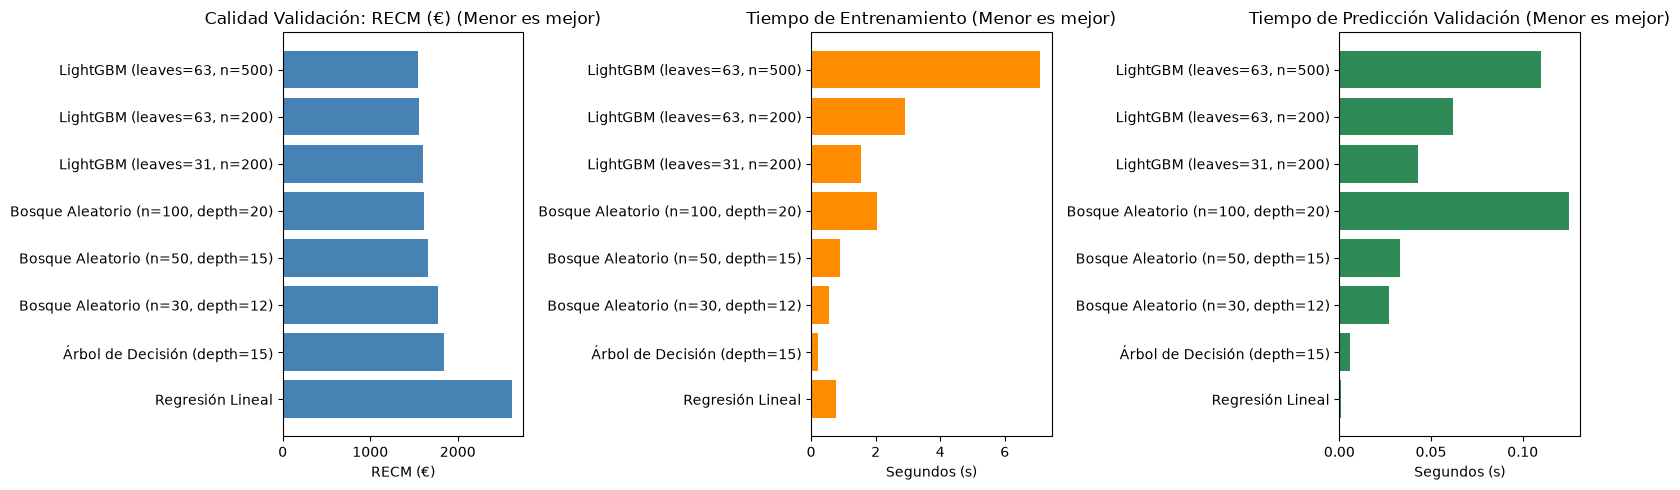

In [14]:
# =======================================================
# TABLA COMPARATIVA Y VISUALIZACIÓN EN VALIDACIÓN (20%)
# =======================================================

df_resultados = pd.DataFrame(resultados).sort_values(by='RECM Validación (Euros)').reset_index(drop=True)
display(df_resultados)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].barh(df_resultados['Modelo'], df_resultados['RECM Validación (Euros)'], color='steelblue')
axes[0].set_title('Calidad Validación: RECM (€) (Menor es mejor)')
axes[0].set_xlabel('RECM (€)')
axes[0].invert_yaxis()

axes[1].barh(df_resultados['Modelo'], df_resultados['Tiempo Entrenamiento (s)'], color='darkorange')
axes[1].set_title('Tiempo de Entrenamiento (Menor es mejor)')
axes[1].set_xlabel('Segundos (s)')
axes[1].invert_yaxis()

axes[2].barh(df_resultados['Modelo'], df_resultados['Tiempo Predicción (s)'], color='seagreen')
axes[2].set_title('Tiempo de Predicción Validación (Menor es mejor)')
axes[2].set_xlabel('Segundos (s)')
axes[2].invert_yaxis()

plt.tight_layout()
plt.show()


#### Evaluación final imparcial en Test (20%) y latencia individual robusta

In [15]:
# =======================================================
# EVALUACIÓN FINAL EN TEST (20%) Y LATENCIA INDIVIDUAL
# =======================================================

# 1. Evaluación por lotes sobre el conjunto reservado de prueba (Test 20%)
t_test = time.perf_counter()
pred_test = lgb_model_3.predict(X_test)
tiempo_pred_test = time.perf_counter() - t_test
recm_test = np.sqrt(mean_squared_error(y_test, pred_test))

# 2. Medición robusta de latencia individual (warm-up + mediana y P95 sobre 50 filas)
for i in range(5):
    _ = lgb_model_3.predict(X_test.iloc[[i]])

latencias_ms = []
for i in range(5, 55):
    fila = X_test.iloc[[i]]
    t0 = time.perf_counter()
    _ = lgb_model_3.predict(fila)
    latencias_ms.append((time.perf_counter() - t0) * 1000)

latencia_mediana_ms = np.median(latencias_ms)
latencia_p95_ms = np.percentile(latencias_ms, 95)

print(f">>> EVALUACIÓN FINAL EN TEST (20%) - LightGBM (leaves=63, n=500) <<<")
print(f"RECM en Prueba (Test): {recm_test:.2f} €")
print(f"Tiempo de predicción por lote ({len(X_test):,} registros): {tiempo_pred_test:.3f} s")
print(f"Latencia de consulta individual (1 vehículo) -> Mediana: {latencia_mediana_ms:.2f} ms | P95: {latencia_p95_ms:.2f} ms")


>>> EVALUACIÓN FINAL EN TEST (20%) - LightGBM (leaves=63, n=500) <<<
RECM en Prueba (Test): 1516.38 €
Tiempo de predicción por lote (65,393 registros): 0.116 s
Latencia de consulta individual (1 vehículo) -> Mediana: 0.81 ms | P95: 1.03 ms


In [16]:
# Indexar df_resultados por el nombre del modelo para extraer cifras exactas
res = df_resultados.set_index('Modelo')

lr = res.loc['Regresión Lineal']
dt = res.loc['Árbol de Decisión (depth=15)']
rf1 = res.loc['Bosque Aleatorio (n=30, depth=12)']
rf2 = res.loc['Bosque Aleatorio (n=50, depth=15)']
rf3 = res.loc['Bosque Aleatorio (n=100, depth=20)']
lgb1 = res.loc['LightGBM (leaves=31, n=200)']
lgb2 = res.loc['LightGBM (leaves=63, n=200)']
lgb3 = res.loc['LightGBM (leaves=63, n=500)']

mejora_hojas = lgb1['RECM Validación (Euros)'] - lgb2['RECM Validación (Euros)']
mejora_arboles = lgb2['RECM Validación (Euros)'] - lgb3['RECM Validación (Euros)']
mejora_total_lgb = lgb1['RECM Validación (Euros)'] - lgb3['RECM Validación (Euros)']

diff_entrenamiento = lgb3['Tiempo Entrenamiento (s)'] - lgb1['Tiempo Entrenamiento (s)']
diff_prediccion = lgb3['Tiempo Predicción (s)'] - lgb1['Tiempo Predicción (s)']
ratio_entrenamiento = lgb3['Tiempo Entrenamiento (s)'] / lgb1['Tiempo Entrenamiento (s)']
ratio_prediccion = lgb3['Tiempo Predicción (s)'] / lgb1['Tiempo Predicción (s)']

texto_hallazgos = f"""
### Conclusiones y hallazgos del análisis

Al evaluar los distintos algoritmos sobre el conjunto de validación ({len(X_valid):,} registros) según los tres criterios prioritarios para **Rusty Bargain** (calidad de predicción medida por RECM, velocidad de predicción y tiempo de entrenamiento), se obtienen los siguientes hallazgos:

1. **Prueba de cordura (Regresión Lineal):** Obtuvo el error más alto (**{lr['RECM Validación (Euros)']:,.2f} €**) y un tiempo de entrenamiento elevado (**{lr['Tiempo Entrenamiento (s)']:.3f} s**) debido a la alta dimensionalidad generada por la codificación *One-Hot*, aunque registró la predicción por lote más rápida de todo el estudio (**{lr['Tiempo Predicción (s)']:.3f} s**). Esto confirma que el precio de mercado no responde a relaciones puramente lineales.
2. **Árbol de Decisión (`max_depth=15`):** Al explorar profundidades entre 5 y 25, se observó *underfitting* en profundidades bajas (`5` y `10`), mientras que `max_depth=20` alcanzó el menor RECM en validación (**{resultados_dt[20]:,.2f} €**) y `max_depth=25` (**{resultados_dt[25]:,.2f} €**) comenzó a degradarse ligeramente. Se seleccionó `max_depth=15` (**{dt['RECM Validación (Euros)']:,.2f} €**) por presentar una menor brecha entre entrenamiento y validación y ser el algoritmo más rápido en entrenar (**{dt['Tiempo Entrenamiento (s)']:.3f} s**), así como el más veloz en predecir entre los modelos basados en árboles (**{dt['Tiempo Predicción (s)']:.3f} s**).
3. **Ajuste de hiperparámetros en Bosque Aleatorio:**
   - `n=30, depth=12`: RECM de **{rf1['RECM Validación (Euros)']:,.2f} €** | Entrenamiento: **{rf1['Tiempo Entrenamiento (s)']:.3f} s** | Predicción: **{rf1['Tiempo Predicción (s)']:.3f} s**.
   - `n=50, depth=15`: RECM de **{rf2['RECM Validación (Euros)']:,.2f} €** | Entrenamiento: **{rf2['Tiempo Entrenamiento (s)']:.3f} s** | Predicción: **{rf2['Tiempo Predicción (s)']:.3f} s**.
   - `n=100, depth=20`: Alcanzó su mejor precisión con **{rf3['RECM Validación (Euros)']:,.2f} €**, pero a un costo de entrenamiento muy elevado (**{rf3['Tiempo Entrenamiento (s)']:.3f} s**) y predicción por lotes de **{rf3['Tiempo Predicción (s)']:.3f} s**. Frente a esta configuración, **LightGBM (`leaves=63, n=500`)** logra un error menor (**{lgb3['RECM Validación (Euros)']:,.2f} €**) y entrena más rápido (**{lgb3['Tiempo Entrenamiento (s)']:.3f} s**), aunque su predicción por lotes (**{lgb3['Tiempo Predicción (s)']:.3f} s**) es más lenta.
4. **Experimento controlado en LightGBM (variando un hiperparámetro a la vez):**
   - *Base (`leaves=31, n=200`):* RECM de **{lgb1['RECM Validación (Euros)']:,.2f} €** | Entrenamiento: **{lgb1['Tiempo Entrenamiento (s)']:.3f} s** | Predicción: **{lgb1['Tiempo Predicción (s)']:.3f} s**.
   - *Incremento de hojas (`leaves=63, n=200`):* Duplicar las hojas manteniendo 200 árboles redujo el error en **{mejora_hojas:.2f} €** (hasta **{lgb2['RECM Validación (Euros)']:,.2f} €**), demostrando que capturar interacciones más profundas aporta la mayor parte de la mejora con un costo moderado (**{lgb2['Tiempo Entrenamiento (s)']:.3f} s** de entrenamiento y **{lgb2['Tiempo Predicción (s)']:.3f} s** de predicción).
   - *Incremento de estimadores (`leaves=63, n=500`):* Aumentar los árboles a 500 aportó una ganancia adicional de **{mejora_arboles:.2f} €**, logrando el mejor RECM global en validación (**{lgb3['RECM Validación (Euros)']:,.2f} €**), aunque incrementando el tiempo de entrenamiento (**{lgb3['Tiempo Entrenamiento (s)']:.3f} s**) y de predicción (**{lgb3['Tiempo Predicción (s)']:.3f} s**).

---

#### Análisis de equilibrio Coste-Beneficio (*Trade-off*) y Recomendación Final
* **Modelo recomendado:** **LightGBM (`num_leaves=63`, `learning_rate=0.1`, `n_estimators=500`)**.
* **Evaluación imparcial en Prueba (Test 20%):** Al evaluar este modelo ganador una única vez sobre el conjunto reservado de prueba ({len(X_test):,} vehículos), obtuvo un **RECM final de {recm_test:,.2f} €**, un rendimiento por lote (*throughput*) de **{tiempo_pred_test:.3f} s** para todo el conjunto y una **latencia mediana de {latencia_mediana_ms:.2f} ms (P95: {latencia_p95_ms:.2f} ms) para devolver la predicción de una sola fila** (1 vehículo).
* **Justificación del *trade-off*:** Frente al modelo base (`leaves=31, n=200`), la versión ajustada mejora el error en **{mejora_total_lgb:.2f} €** a cambio de un incremento de **+{diff_entrenamiento:.2f} s** (×{ratio_entrenamiento:.1f}) en entrenamiento y **+{diff_prediccion:.2f} s** (×{ratio_prediccion:.1f}) en predicción por lotes. Dado que el entrenamiento se ejecuta de forma periódica *offline* en el servidor (~{lgb3['Tiempo Entrenamiento (s)']:.1f} segundos es un costo despreciable) y la latencia individual mediana en la app sigue siendo de apenas **{latencia_mediana_ms:.2f} milisegundos** (imperceptible para el usuario), **merece la pena priorizar la máxima exactitud en la tasación** para generar confianza en los clientes.
* **Alternativa económica:** Si en el futuro Rusty Bargain necesitara procesar volúmenes masivos de tasaciones simultáneas con recursos de servidor muy limitados, **`LightGBM (leaves=63, n=200)`** o **`LightGBM (leaves=31, n=200)`** representan excelentes alternativas de bajo costo computacional con una pérdida mínima de precisión.

---
"""

display(Markdown(texto_hallazgos))



### Conclusiones y hallazgos del análisis

Al evaluar los distintos algoritmos sobre el conjunto de validación (65,393 registros) según los tres criterios prioritarios para **Rusty Bargain** (calidad de predicción medida por RECM, velocidad de predicción y tiempo de entrenamiento), se obtienen los siguientes hallazgos:

1. **Prueba de cordura (Regresión Lineal):** Obtuvo el error más alto (**2,618.10 €**) y un tiempo de entrenamiento elevado (**0.780 s**) debido a la alta dimensionalidad generada por la codificación *One-Hot*, aunque registró la predicción por lote más rápida de todo el estudio (**0.001 s**). Esto confirma que el precio de mercado no responde a relaciones puramente lineales.
2. **Árbol de Decisión (`max_depth=15`):** Al explorar profundidades entre 5 y 25, se observó *underfitting* en profundidades bajas (`5` y `10`), mientras que `max_depth=20` alcanzó el menor RECM en validación (**1,823.36 €**) y `max_depth=25` (**1,825.62 €**) comenzó a degradarse ligeramente. Se seleccionó `max_depth=15` (**1,839.97 €**) por presentar una menor brecha entre entrenamiento y validación y ser el algoritmo más rápido en entrenar (**0.225 s**), así como el más veloz en predecir entre los modelos basados en árboles (**0.006 s**).
3. **Ajuste de hiperparámetros en Bosque Aleatorio:**
   - `n=30, depth=12`: RECM de **1,768.99 €** | Entrenamiento: **0.544 s** | Predicción: **0.027 s**.
   - `n=50, depth=15`: RECM de **1,657.95 €** | Entrenamiento: **0.883 s** | Predicción: **0.033 s**.
   - `n=100, depth=20`: Alcanzó su mejor precisión con **1,617.76 €**, pero a un costo de entrenamiento muy elevado (**2.037 s**) y predicción por lotes de **0.125 s**. Frente a esta configuración, **LightGBM (`leaves=63, n=500`)** logra un error menor (**1,541.82 €**) y entrena más rápido (**7.097 s**), aunque su predicción por lotes (**0.110 s**) es más lenta.
4. **Experimento controlado en LightGBM (variando un hiperparámetro a la vez):**
   - *Base (`leaves=31, n=200`):* RECM de **1,597.15 €** | Entrenamiento: **1.545 s** | Predicción: **0.043 s**.
   - *Incremento de hojas (`leaves=63, n=200`):* Duplicar las hojas manteniendo 200 árboles redujo el error en **35.14 €** (hasta **1,562.01 €**), demostrando que capturar interacciones más profundas aporta la mayor parte de la mejora con un costo moderado (**2.904 s** de entrenamiento y **0.062 s** de predicción).
   - *Incremento de estimadores (`leaves=63, n=500`):* Aumentar los árboles a 500 aportó una ganancia adicional de **20.19 €**, logrando el mejor RECM global en validación (**1,541.82 €**), aunque incrementando el tiempo de entrenamiento (**7.097 s**) y de predicción (**0.110 s**).

---

#### Análisis de equilibrio Coste-Beneficio (*Trade-off*) y Recomendación Final
* **Modelo recomendado:** **LightGBM (`num_leaves=63`, `learning_rate=0.1`, `n_estimators=500`)**.
* **Evaluación imparcial en Prueba (Test 20%):** Al evaluar este modelo ganador una única vez sobre el conjunto reservado de prueba (65,393 vehículos), obtuvo un **RECM final de 1,516.38 €**, un rendimiento por lote (*throughput*) de **0.116 s** para todo el conjunto y una **latencia mediana de 0.81 ms (P95: 1.03 ms) para devolver la predicción de una sola fila** (1 vehículo).
* **Justificación del *trade-off*:** Frente al modelo base (`leaves=31, n=200`), la versión ajustada mejora el error en **55.33 €** a cambio de un incremento de **+5.55 s** (×4.6) en entrenamiento y **+0.07 s** (×2.6) en predicción por lotes. Dado que el entrenamiento se ejecuta de forma periódica *offline* en el servidor (~7.1 segundos es un costo despreciable) y la latencia individual mediana en la app sigue siendo de apenas **0.81 milisegundos** (imperceptible para el usuario), **merece la pena priorizar la máxima exactitud en la tasación** para generar confianza en los clientes.
* **Alternativa económica:** Si en el futuro Rusty Bargain necesitara procesar volúmenes masivos de tasaciones simultáneas con recursos de servidor muy limitados, **`LightGBM (leaves=63, n=200)`** o **`LightGBM (leaves=31, n=200)`** representan excelentes alternativas de bajo costo computacional con una pérdida mínima de precisión.

---


In [17]:
texto_conclusiones_generales = f"""
## Conclusiones generales del proyecto

El proyecto cumplió con el objetivo de desarrollar y validar un motor de tasación de autos usados para **Rusty Bargain**, equilibrando precisión predictiva (**RECM**) y eficiencia computacional.

### Aprendizajes clave y decisión final
* **Integridad de datos sin fuga (*data leakage*):** Conservar los registros legítimos (eliminando solo los **{duplicates_count:,}** duplicados exactos originales), imputar las categorías faltantes antes de agrupar y aprender las medianas de potencia y codificadores únicamente sobre el conjunto de entrenamiento (`60%`) permitió obtener **{len(df):,} registros limpios** y una evaluación imparcial.
* **Superioridad del *Gradient Boosting*:** La validación (`20%`) demostró que los modelos lineales (**{lr['RECM Validación (Euros)']:,.2f} €**) no capturan la complejidad no lineal del mercado, mientras que los ensambles de mayor capacidad y LightGBM superan claramente a un árbol individual (**{dt['RECM Validación (Euros)']:,.2f} €**). Entre los ensambles, **LightGBM (`leaves=63, n=500`)** obtuvo el menor error (**{lgb3['RECM Validación (Euros)']:,.2f} €**) y entrenó más rápido (**{lgb3['Tiempo Entrenamiento (s)']:.3f} s**) que el Bosque Aleatorio de exactitud más cercana (**{rf3['RECM Validación (Euros)']:,.2f} €** en **{rf3['Tiempo Entrenamiento (s)']:.3f} s**), asumiendo a cambio el mayor tiempo de predicción por lotes (**{lgb3['Tiempo Predicción (s)']:.3f} s**).
* **Modelo seleccionado para producción:** Se recomienda implementar **`LightGBM (num_leaves=63, learning_rate=0.1, n_estimators=500)`**. En su evaluación final sobre el conjunto reservado de prueba (`20%`, {len(X_test):,} vehículos), alcanzó un **RECM de {recm_test:,.2f} €**, con un tiempo de procesamiento por lote de **{tiempo_pred_test:.3f} s** y una **latencia mediana de {latencia_mediana_ms:.2f} ms (P95: {latencia_p95_ms:.2f} ms) para devolver la predicción de una sola fila**, garantizando tasaciones altamente precisas y en tiempo real dentro de la aplicación (con `leaves=63, n=200` o `leaves=31, n=200` como alternativas más ligeras si se prioriza la velocidad de inferencia).
"""

display(Markdown(texto_conclusiones_generales))



## Conclusiones generales del proyecto

El proyecto cumplió con el objetivo de desarrollar y validar un motor de tasación de autos usados para **Rusty Bargain**, equilibrando precisión predictiva (**RECM**) y eficiencia computacional.

### Aprendizajes clave y decisión final
* **Integridad de datos sin fuga (*data leakage*):** Conservar los registros legítimos (eliminando solo los **262** duplicados exactos originales), imputar las categorías faltantes antes de agrupar y aprender las medianas de potencia y codificadores únicamente sobre el conjunto de entrenamiento (`60%`) permitió obtener **326,965 registros limpios** y una evaluación imparcial.
* **Superioridad del *Gradient Boosting*:** La validación (`20%`) demostró que los modelos lineales (**2,618.10 €**) no capturan la complejidad no lineal del mercado, mientras que los ensambles de mayor capacidad y LightGBM superan claramente a un árbol individual (**1,839.97 €**). Entre los ensambles, **LightGBM (`leaves=63, n=500`)** obtuvo el menor error (**1,541.82 €**) y entrenó más rápido (**7.097 s**) que el Bosque Aleatorio de exactitud más cercana (**1,617.76 €** en **2.037 s**), asumiendo a cambio el mayor tiempo de predicción por lotes (**0.110 s**).
* **Modelo seleccionado para producción:** Se recomienda implementar **`LightGBM (num_leaves=63, learning_rate=0.1, n_estimators=500)`**. En su evaluación final sobre el conjunto reservado de prueba (`20%`, 65,393 vehículos), alcanzó un **RECM de 1,516.38 €**, con un tiempo de procesamiento por lote de **0.116 s** y una **latencia mediana de 0.81 ms (P95: 1.03 ms) para devolver la predicción de una sola fila**, garantizando tasaciones altamente precisas y en tiempo real dentro de la aplicación (con `leaves=63, n=200` o `leaves=31, n=200` como alternativas más ligeras si se prioriza la velocidad de inferencia).
